<a href="https://colab.research.google.com/github/tanvi118/NLP_Lab/blob/main/NLP_Exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tanvi Vitankar, 500120658, exp-6

In [1]:
!pip -q install kagglehub nltk pandas matplotlib

In [2]:
import os
import re
import math
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
DATASET_HANDLE = "ffatty/english-news-sentence-corpus"

dataset_path = kagglehub.dataset_download(DATASET_HANDLE)

print("Dataset downloaded to:")
print(dataset_path)

for root, dirs, files in os.walk(dataset_path):
    for file in files[:10]:
        print(os.path.join(root, file))

100%|██████████| 976M/976M [00:15<00:00, 66.5MB/s]

Extracting files...


Dataset downloaded to:
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/all_news_sentences.txt
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/news_sentences/eng_news_sentences_2009.txt
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/news_sentences/eng_news_sentences_2018.txt
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/news_sentences/eng_newscrawl_sentences_2015.txt
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/news_sentences/eng_news_sentences_2014.txt
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/news_sentences/eng_news_sentences_2023.txt
/root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/news_sentences/eng_news_sentences_2006.txt
/root/.cache/kagglehub/datasets/ffatty/english-news-sentenc

In [4]:
candidate_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower() in {
            "all_news_sentences.txt",
            "news_sentences.txt",
            "sentences.txt"
        }:
            candidate_files.append(os.path.join(root, file))

if not candidate_files:
    for root, dirs, files in os.walk(dataset_path):
        for file in files:
            if file.lower().endswith(".txt"):
                candidate_files.append(os.path.join(root, file))

if not candidate_files:
    raise FileNotFoundError("No suitable .txt corpus file was found.")

CORPUS_FILE = candidate_files[0]
print("Using corpus:", CORPUS_FILE)

Using corpus: /root/.cache/kagglehub/datasets/ffatty/english-news-sentence-corpus/versions/1/all_news_sentences.txt


In [5]:
MAX_SENTENCES = 10000

with open(CORPUS_FILE, "r", encoding="utf-8", errors="ignore") as f:
    raw_lines = [line.strip() for line in f if line.strip()]

random.seed(42)
random.shuffle(raw_lines)

sentences = raw_lines[:MAX_SENTENCES]

print("Number of sentences used:", len(sentences))
print("\nSample sentences:")

for s in sentences[:5]:
    print("-", s[:200])

Number of sentences used: 10000

Sample sentences:
- 350020	In 2016, the St. Patrick's Island took top honours in the Great Public Space category in the Canadian Institute of Planners' Great Places in Canada competition.
- 458926	Kyle Feldt bombed a certain try off a Thurston kick not long after.
- 589179	Has Iraq improved since the war?
- 234397	There is no reason to assume that water would cause more warfare than oil or national pride.
- 507714	Next, inventories are falling.


In [6]:
def tokenize_sentence(sentence):
    sentence = sentence.lower()
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", sentence)
    return ["<s>"] + tokens + ["</s>"]


tokenized_sentences = [
    tokenize_sentence(sentence)
    for sentence in sentences
]

tokenized_sentences = [
    sentence for sentence in tokenized_sentences
    if len(sentence) >= 3
]

print("Usable sentences:", len(tokenized_sentences))
print("Example tokens:", tokenized_sentences[0])

Usable sentences: 10000
Example tokens: ['<s>', 'in', 'the', 'st', "patrick's", 'island', 'took', 'top', 'honours', 'in', 'the', 'great', 'public', 'space', 'category', 'in', 'the', 'canadian', 'institute', 'of', 'planners', 'great', 'places', 'in', 'canada', 'competition', '</s>']


In [7]:
random.seed(42)
random.shuffle(tokenized_sentences)

split = int(0.8 * len(tokenized_sentences))

train_sentences = tokenized_sentences[:split]
test_sentences = tokenized_sentences[split:]

print("Training sentences:", len(train_sentences))
print("Testing sentences :", len(test_sentences))

vocab = set()

for sentence in train_sentences:
    vocab.update(sentence)

vocab.add("<UNK>")

print("Vocabulary size:", len(vocab))

Training sentences: 8000
Testing sentences : 2000
Vocabulary size: 20227


In [8]:
def generate_ngrams(tokens, n):
    return [
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    ]


def build_ngram_counts(sentences, n):
    counts = Counter()

    for sentence in sentences:
        counts.update(generate_ngrams(sentence, n))

    return counts


unigram_counts = build_ngram_counts(train_sentences, 1)
bigram_counts = build_ngram_counts(train_sentences, 2)
trigram_counts = build_ngram_counts(train_sentences, 3)

print("Unique unigrams :", len(unigram_counts))
print("Unique bigrams  :", len(bigram_counts))
print("Unique trigrams :", len(trigram_counts))

Unique unigrams : 20226
Unique bigrams  : 101579
Unique trigrams : 142959


In [9]:
def show_top_ngrams(counter, n=10):
    rows = []

    for gram, count in counter.most_common(n):
        rows.append((" ".join(gram), count))

    return pd.DataFrame(
        rows,
        columns=["N-Gram", "Count"]
    )


print("Top Bigrams")
display(show_top_ngrams(bigram_counts, 10))

print("Top Trigrams")
display(show_top_ngrams(trigram_counts, 10))

Top Bigrams


,N-Gram,Count
0,of the,949
1,<s> the,945
2,in the,880
3,to the,428
4,on the,346
5,for the,308
6,at the,297
7,said </s>,276
8,<s> i,269
9,and the,249


Top Trigrams


,N-Gram,Count
0,one of the,66
1,<s> it s,55
2,he said </s>,52
3,<s> it was,45
4,<s> in the,44
5,a lot of,39
6,the u s,36
7,according to the,36
8,<s> it is,34
9,<s> but the,34


In [10]:
def mle_bigram_probability(w1, w2):
    numerator = bigram_counts[(w1, w2)]
    denominator = unigram_counts[(w1,)]

    if denominator == 0:
        return 0.0

    return numerator / denominator


def mle_trigram_probability(w1, w2, w3):
    numerator = trigram_counts[(w1, w2, w3)]
    denominator = bigram_counts[(w1, w2)]

    if denominator == 0:
        return 0.0

    return numerator / denominator


examples = [
    ("the", "government"),
    ("machine", "learning"),
    ("new", "york")
]

for w1, w2 in examples:
    print(
        f"P({w2}|{w1}) =",
        mle_bigram_probability(w1, w2)
    )

P(government|the) = 0.004648648648648649
P(learning|machine) = 0.0
P(york|new) = 0.1245674740484429


In [11]:
test_pairs = [
    ("xyzabc", "qwerty"),
    ("machine", "learning"),
    ("the", "government")
]

for w1, w2 in test_pairs:
    print(
        f"P({w2}|{w1}) =",
        mle_bigram_probability(w1, w2)
    )

P(qwerty|xyzabc) = 0.0
P(learning|machine) = 0.0
P(government|the) = 0.004648648648648649


In [12]:
V = len(vocab)


def laplace_bigram_probability(w1, w2):
    count_bigram = bigram_counts[(w1, w2)]
    count_history = unigram_counts[(w1,)]

    return (count_bigram + 1) / (count_history + V)


def laplace_trigram_probability(w1, w2, w3):
    count_trigram = trigram_counts[(w1, w2, w3)]
    count_history = bigram_counts[(w1, w2)]

    return (count_trigram + 1) / (count_history + V)


for w1, w2 in test_pairs:
    print(
        f"Laplace P({w2}|{w1}) =",
        f"{laplace_bigram_probability(w1, w2):.10f}"
    )

Laplace P(qwerty|xyzabc) = 0.0000494389
Laplace P(learning|machine) = 0.0000494291
Laplace P(government|the) = 0.0014926892


In [13]:
def normalize_for_vocab(tokens):
    return [
        token if token in vocab else "<UNK>"
        for token in tokens
    ]


def sentence_probability_bigram(sentence, smoothing=False):
    tokens = normalize_for_vocab(
        tokenize_sentence(sentence)
    )

    log_probability = 0.0

    for i in range(1, len(tokens)):
        w1 = tokens[i - 1]
        w2 = tokens[i]

        if smoothing:
            probability = laplace_bigram_probability(w1, w2)
        else:
            probability = mle_bigram_probability(w1, w2)

        if probability == 0:
            return 0.0

        log_probability += math.log(probability)

    return math.exp(log_probability)


sample_sentence = "machine learning is useful"

print("Sentence:", sample_sentence)
print(
    "MLE probability:",
    sentence_probability_bigram(
        sample_sentence,
        smoothing=False
    )
)

print(
    "Laplace probability:",
    sentence_probability_bigram(
        sample_sentence,
        smoothing=True
    )
)

Sentence: machine learning is useful
MLE probability: 0.0
Laplace probability: 3.9365508511615806e-22


In [14]:
def perplexity_bigram(test_data, smoothing=True):
    total_log_prob = 0.0
    total_predictions = 0

    for sentence in test_data:
        tokens = normalize_for_vocab(sentence)

        for i in range(1, len(tokens)):
            w1 = tokens[i - 1]
            w2 = tokens[i]

            if smoothing:
                probability = laplace_bigram_probability(w1, w2)
            else:
                probability = mle_bigram_probability(w1, w2)

            if probability <= 0:
                return float("inf")

            total_log_prob += math.log(probability)
            total_predictions += 1

    return math.exp(
        -total_log_prob / total_predictions
    )


print(
    "Laplace-smoothed bigram perplexity:",
    perplexity_bigram(
        test_sentences,
        smoothing=True
    )
)

print(
    "Unsmoothed bigram perplexity:",
    perplexity_bigram(
        test_sentences,
        smoothing=False
    )
)

Laplace-smoothed bigram perplexity: 6962.942964415433
Unsmoothed bigram perplexity: inf


In [15]:
evaluation_sentences = [
    "the government announced a new policy",
    "machine learning is used in many applications",
    "artificial intelligence is changing technology",
    "the quick brown fox jumps over the lazy dog"
]

results = []

for sentence in evaluation_sentences:
    mle = sentence_probability_bigram(
        sentence,
        smoothing=False
    )

    laplace = sentence_probability_bigram(
        sentence,
        smoothing=True
    )

    results.append({
        "Sentence": sentence,
        "MLE Probability": mle,
        "Laplace Probability": laplace
    })

results_df = pd.DataFrame(results)
display(results_df)

,Sentence,MLE Probability,Laplace Probability
0,the government announced a new policy,0.0,1.190597e-23
1,machine learning is used in many applications,0.0,2.526705e-32
2,artificial intelligence is changing technology,0.0,2.333117e-25
3,the quick brown fox jumps over the lazy dog,0.0,3.461920e-39


In [16]:
def predict_next_word(previous_word, top_k=10):
    previous_word = previous_word.lower()

    candidates = []
    denominator = unigram_counts[(previous_word,)]

    if denominator == 0:
        return pd.DataFrame(
            columns=["Next Word", "Probability"]
        )

    for (w1, w2), count in bigram_counts.items():
        if w1 == previous_word:
            candidates.append(
                (w2, count / denominator)
            )

    candidates.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return pd.DataFrame(
        candidates[:top_k],
        columns=["Next Word", "Probability"]
    )


display(predict_next_word("machine", 10))

,Next Word,Probability
0,pitch,0.25
1,mdash,0.25
2,a,0.25
3,that,0.25


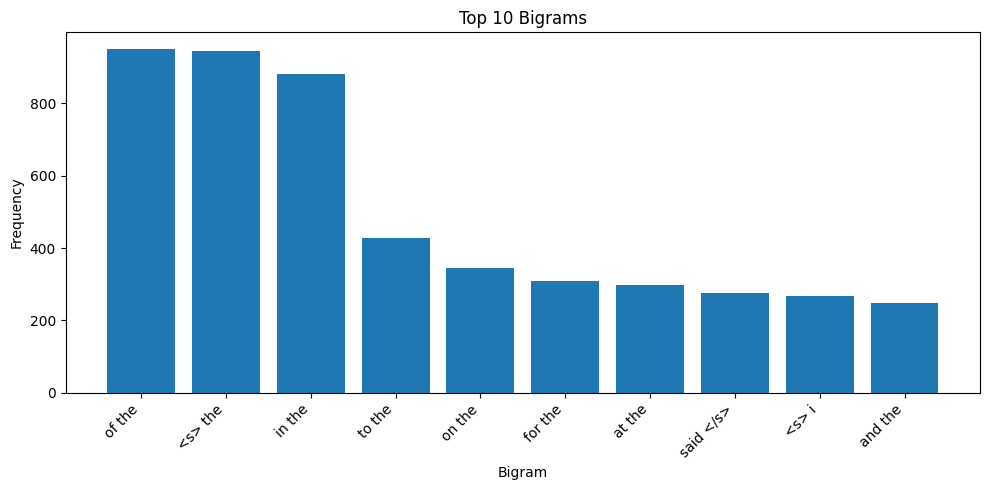

In [17]:
top10 = bigram_counts.most_common(10)

labels = [
    " ".join(gram)
    for gram, count in top10
]

values = [
    count
    for gram, count in top10
]

plt.figure(figsize=(10, 5))
plt.bar(labels, values)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.xlabel("Bigram")
plt.ylabel("Frequency")
plt.title("Top 10 Bigrams")

plt.tight_layout()
plt.show()